# Data overview for the paper

The figures and tables of Section 3 ("Markets and selection"), drawn from exactly the contests the analysis uses:
- **Training:** the 216 US contests from November 2023 to September 2026 that passed every rule.
- **Midterms:** the 332 contests in the pre-registered midterm test (the same sample as `fit/midterm_test.py`).

Office categories and the tile map follow `cleaning/overview.ipynb`. Volume is each contest's total traded volume over its
life, summed over its two candidate markets: contracts on Kalshi, dollars on Polymarket. Figures go to `figures/`,
tables to `tables/`.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

sys.path.insert(0, "../fit")
import midterm_test
import stretch

FIGURES, TABLES = Path("figures"), Path("tables")
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)
STAGE = "final" if Path("../fit/results/midterm_test_final.csv").exists() else "preliminary"

GENERAL, PRIMARY, MIDTERMS = "#2a78d6", "#eb6834", "#1baf7a"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
EMPTY_TILE = "#f0efec"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
GROUPS = {"Training, general": GENERAL, "Training, primary": PRIMARY, "Midterms 2026": MIDTERMS}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "figure.dpi": 110, "text.parse_math": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def compact(value, _=None):
    for size, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if value >= size:
            return f"{value / size:.3g}{suffix}"
    return f"{value:g}"

## The contests

One row per contest in the analysis: its platform, group, state, office and lifetime volume.

In [2]:
prices = pd.read_csv(stretch.PRICES, dtype={"contest_id": str})
training = prices[(prices["country"] == "United States") & prices["included"]
                  & (prices["election_key"] != midterm_test.TEST_DAY)].copy()
training["group"] = np.where(training["kind"] == "general", "Training, general", "Training, primary")
midterms = pd.concat([midterm_test.night(p, midterm_test.TEST_DAY, midterm_test.TEST_SNAPSHOT,
                                         midterm_test.RUNOFF_STATES)[0] for p in ("Kalshi", "Polymarket")])
midterms = prices.merge(midterms[["platform", "contest_id"]], on=["platform", "contest_id"])
midterms["group"] = "Midterms 2026"
contests = pd.concat([training, midterms], ignore_index=True)
contests["state"] = contests["state"].fillna("none")

# Offices: the midterm list names each race; earlier contests are judged on their titles
# (cleaning/overview.ipynb's rules, with lieutenant governor checked before governor).
race = pd.read_csv("../calendar_and_prices/midterm_contests.csv", dtype={"contest_id": str})
race = race.set_index(["platform", "contest_id"])["race"]


def office_of_race(name):
    rules = [("US House", r"^US House"), ("US Senate", r"^US Senate"), ("Governor", r"^Governor"),
             ("Courts", r"Supreme Court|Court"), ("State legislature", r"^State (Senate|House)"),
             ("Local", r"^Mayor|^County")]
    return next((office for office, pattern in rules if re.search(pattern, name)), "Other statewide")


def office_of_title(title, contest_id):
    rules = [
        ("President", contest_id.startswith("PRESPARTY") or re.search(r"Presidential Election|^Who will win [A-Z][a-z]+( [A-Z][a-z]+)?\?$", title)),
        ("State legislature", re.search(r"State Senate|State Assembly|House District|House of Representatives District", title)),
        ("US Senate", contest_id.startswith("SENATE") or re.search(r"\bSenate\b", title)),
        ("US House", contest_id.startswith("HOUSE") or re.search(r"[A-Z]{2}-(\d+|AL)\b|House race|ongressional", title)),
        ("Other statewide", re.search(r"Lt\. Gov|Lieutenant Governor", title)),
        ("Governor", contest_id.startswith("GOVPARTY") or re.search(r"Governor|gubernatorial", title, re.I)),
        ("Courts", re.search(r"Court", title)),
        ("Other statewide", re.search(r"Attorney General|attorney general|Secretary of State|Treasurer|Superintendent|Commissioner|Commission|Comptroller|Auditor", title)),
        ("Local", re.search(r"[Mm]ayor|City Council|County Executive|Borough President|County Judge", title)),
    ]
    return next((name for name, hit in rules if hit), "Other")


contests["office"] = [office_of_race(race[(p, c)]) if g == "Midterms 2026" else office_of_title(t, c)
                      for p, c, t, g in zip(contests["platform"], contests["contest_id"], contests["title"], contests["group"])]

# Volume: lifetime contracts (Kalshi) or dollars (Polymarket) in the two candidate markets
volume = {}
for path in ("../cleaning/kalshi_binary_elections.json", "../cleaning/midterm_kalshi_binary.json"):
    for m in json.loads(Path(path).read_text()):
        volume[("Kalshi", m["event_ticker"])] = volume.get(("Kalshi", m["event_ticker"]), 0.0) + float(m.get("volume_fp") or m.get("volume") or 0)
for path in ("../cleaning/polymarket_binary_elections.json", "../cleaning/midterm_polymarket_binary.json"):
    for e in json.loads(Path(path).read_text()):
        baskets = {str(b) for b in (e.get("basket_market_ids") or [])}
        volume[("Polymarket", str(e["id"]))] = sum(float(m.get("volumeNum") or 0) for m in e["markets"]
                                                   if str(m["id"]) not in baskets)
contests["volume"] = [volume.get((p, c), np.nan) for p, c in zip(contests["platform"], contests["contest_id"])]
contests["favourite"] = contests[["p_a", "p_b"]].max(axis=1)

assert contests["volume"].notna().all(), contests[contests["volume"].isna()][["platform", "contest_id", "title"]]
assert (contests["office"] != "Other").all(), contests[contests["office"] == "Other"][["platform", "title"]]
contests[["platform", "group", "contest_id", "title", "state", "office", "volume", "favourite"]].to_csv(
    TABLES / f"contests_{STAGE}.csv", index=False)
contests.groupby(["platform", "group"]).size().unstack()

group,Midterms 2026,"Training, general","Training, primary"
platform,,,
Kalshi,187,74,78
Polymarket,145,41,23


## Selection, step by step

How many contests survive each step, per platform. The first two training rows count every country, because the
pulls and the cleaning cover all elections; the analysis keeps the US contests only.

In [3]:
def report_number(path, pattern):
    return int(re.search(pattern, Path(path).read_text()).group(1))


us_cleaned = prices[(prices["country"] == "United States") & (prices["election_key"] != midterm_test.TEST_DAY)]
decisions = pd.read_csv("../cleaning/midterm_decisions_after_vote.csv", dtype={"contest_id": str})
mid_priced = prices[prices["election_key"] == midterm_test.TEST_DAY]
rows = [
    ("Training", "Settled election events pulled (all countries)",
     report_number("../cleaning/kalshi_binary_report.txt", r"Input events: (\d+)"),
     report_number("../cleaning/polymarket_binary_report.txt", r"\((\d+) events\)")),
    ("Training", "Two candidates, one race, one clear winner (all countries)",
     report_number("../cleaning/kalshi_binary_report.txt", r"Events kept after duplicate removal: (\d+)"),
     report_number("../cleaning/polymarket_binary_report.txt", r"Kept: (\d+)")),
    ("Training", "  of which in the US", *[(us_cleaned["platform"] == p).sum() for p in ("Kalshi", "Polymarket")]),
    ("Training", "Passed the price rules (analysed)", *[((training["platform"] == p)).sum() for p in ("Kalshi", "Polymarket")]),
    ("Midterms", "Listed before the vote", *[(race.index.get_level_values(0) == p).sum() for p in ("Kalshi", "Polymarket")]),
    ("Midterms", "Settled by 10 November with a listed candidate winning",
     *[((decisions["platform"] == p) & (decisions["reason"] == "kept")).sum() for p in ("Kalshi", "Polymarket")]),
    ("Midterms", "Passed the price rules", *[((mid_priced["platform"] == p) & mid_priced["included"]).sum() for p in ("Kalshi", "Polymarket")]),
    ("Midterms", "Outside Georgia, Louisiana and Mississippi (tested)",
     *[(midterms["platform"] == p).sum() for p in ("Kalshi", "Polymarket")]),
]
selection = pd.DataFrame(rows, columns=["period", "step", "Kalshi", "Polymarket"])
selection.to_csv(TABLES / f"selection_{STAGE}.csv", index=False)
selection

,period,step,Kalshi,Polymarket
0,Training,Settled election events pulled (all countries),2062,2777
1,Training,"Two candidates, one race, one clear winner (al...",391,224
2,Training,of which in the US,344,179
3,Training,Passed the price rules (analysed),152,64
4,Midterms,Listed before the vote,572,521
5,Midterms,Settled by 10 November with a listed candidate...,548,499
6,Midterms,Passed the price rules,197,152
7,Midterms,"Outside Georgia, Louisiana and Mississippi (te...",187,145


In [4]:
# Why contests that reached pricing were dropped (US only)
priced_us = prices[prices["country"] == "United States"].copy()
priced_us["period"] = np.where(priced_us["election_key"] == midterm_test.TEST_DAY, "Midterms", "Training")
reasons = (priced_us.groupby(["reason", "period", "platform"]).size().unstack(["period", "platform"], fill_value=0)
           .reindex(columns=pd.MultiIndex.from_product([["Training", "Midterms"], ["Kalshi", "Polymarket"]]), fill_value=0))
reasons = reasons.loc[reasons.sum(axis=1).sort_values(ascending=False).index]
reasons.to_csv(TABLES / f"price_rules_{STAGE}.csv")
reasons

Training             \
                                                     Kalshi Polymarket   
reason                                                                   
drop: favourite above 95% (scaled)                      183         91   
kept                                                    152         64   
drop: neither candidate traded in the 24 hours ...        0          8   
drop: another candidate priced above 5%                   0         10   
drop: no quote within 10 cents and no trade in ...        7          0   
drop: prices of all options add up to more than...        1          5   
drop: market opened after the snapshot                    1          1   

                                                   Midterms             
                                                     Kalshi Polymarket  
reason                                                                  
drop: favourite above 95% (scaled)                      350        298  
kept                                                    197        152  
drop: neither candidate traded in the 24 hours ...        0         48  
drop: another candidate priced above 5%                   0          1  
drop: no quote within 10 cents and no trade in ...        1          0  
drop: prices of all options add up to more than...        0          0  
drop: market opened after the snapshot                    0          0

## Where the contests are

Contests per state, both platforms together. Training contests (general elections and primaries) on the left, the
midterm test on the right. The colour scale is set separately in each map.

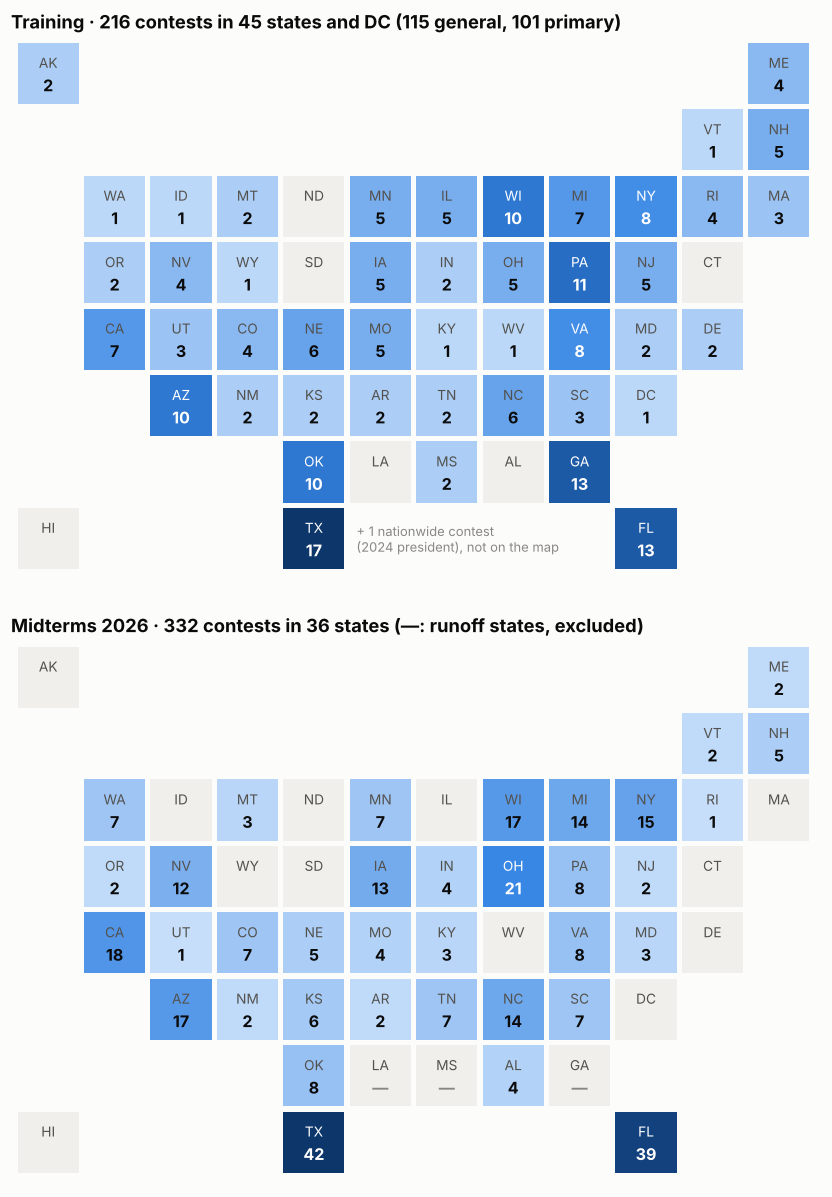

In [5]:
TILES = {
    "AK": (0, 0), "ME": (11, 0), "VT": (10, 1), "NH": (11, 1),
    "WA": (1, 2), "ID": (2, 2), "MT": (3, 2), "ND": (4, 2), "MN": (5, 2), "IL": (6, 2), "WI": (7, 2),
    "MI": (8, 2), "NY": (9, 2), "RI": (10, 2), "MA": (11, 2),
    "OR": (1, 3), "NV": (2, 3), "WY": (3, 3), "SD": (4, 3), "IA": (5, 3), "IN": (6, 3), "OH": (7, 3),
    "PA": (8, 3), "NJ": (9, 3), "CT": (10, 3),
    "CA": (1, 4), "UT": (2, 4), "CO": (3, 4), "NE": (4, 4), "MO": (5, 4), "KY": (6, 4), "WV": (7, 4),
    "VA": (8, 4), "MD": (9, 4), "DE": (10, 4),
    "AZ": (2, 5), "NM": (3, 5), "KS": (4, 5), "AR": (5, 5), "TN": (6, 5), "NC": (7, 5), "SC": (8, 5),
    "DC": (9, 5),
    "OK": (4, 6), "LA": (5, 6), "MS": (6, 6), "AL": (7, 6), "GA": (8, 6),
    "HI": (0, 7), "TX": (4, 7), "FL": (9, 7),
}


def tile_map(ax, counts, title, excluded=()):
    top = max(counts.max(), 1)
    for state, (col, row) in TILES.items():
        n = int(counts.get(state, 0))
        dark = n and n / top > 0.45
        colour = BLUES(n / top) if n else EMPTY_TILE
        ax.add_patch(plt.Rectangle((col, -row), 0.92, 0.92, color=colour, linewidth=0))
        ax.text(col + 0.46, -row + 0.62, state, ha="center", va="center", fontsize=9, color="white" if dark else INK_2)
        label = "—" if state in excluded else (str(n) if n else "")
        ax.text(col + 0.46, -row + 0.28, label, ha="center", va="center", fontsize=10.5, weight="bold",
                color="white" if dark else (MUTED if state in excluded else INK))
    ax.set_title(title, fontsize=12)
    ax.set_xlim(-0.1, 12.1); ax.set_ylim(-7.2, 1.0); ax.set_aspect("equal"); ax.axis("off")


fig, axes = plt.subplots(2, 1, figsize=(8.2, 11))
train_counts = training.groupby("state").size()
mid_counts = midterms.groupby("state").size()
on_map = lambda counts: counts[counts.index.isin(list(TILES))]
national = int(train_counts[~train_counts.index.isin(list(TILES))].sum())
tile_map(axes[0], train_counts, f"Training · {len(training)} contests in {on_map(train_counts).size} states and DC "
                                f"({(training['kind'] == 'general').sum()} general, {(training['kind'] == 'primary').sum()} primary)")
tile_map(axes[1], mid_counts, f"Midterms 2026 · {len(midterms)} contests in {on_map(mid_counts).size} states "
                              f"(—: runoff states, excluded)", excluded=midterm_test.RUNOFF_STATES)
if national:
    axes[0].text(5.1, -6.55, f"+ {national} nationwide contest{'s' if national > 1 else ''}\n(2024 president), not on the map",
                 fontsize=8.5, color=MUTED, va="center")
fig.tight_layout(h_pad=2)
save(fig, "data_states")

## Which offices

Contests per office on each platform, split into training general elections, training primaries and the midterm test.

group,"Training, general","Training, primary",Midterms 2026,platform
office,,,,
US House,24,66,112,Kalshi
US Senate,12,2,10,Kalshi
Governor,5,0,14,Kalshi
Other statewide,4,9,37,Kalshi
President,21,0,0,Kalshi
Courts,5,0,8,Kalshi
State legislature,2,0,3,Kalshi
Local,1,1,3,Kalshi
US House,5,16,105,Polymarket


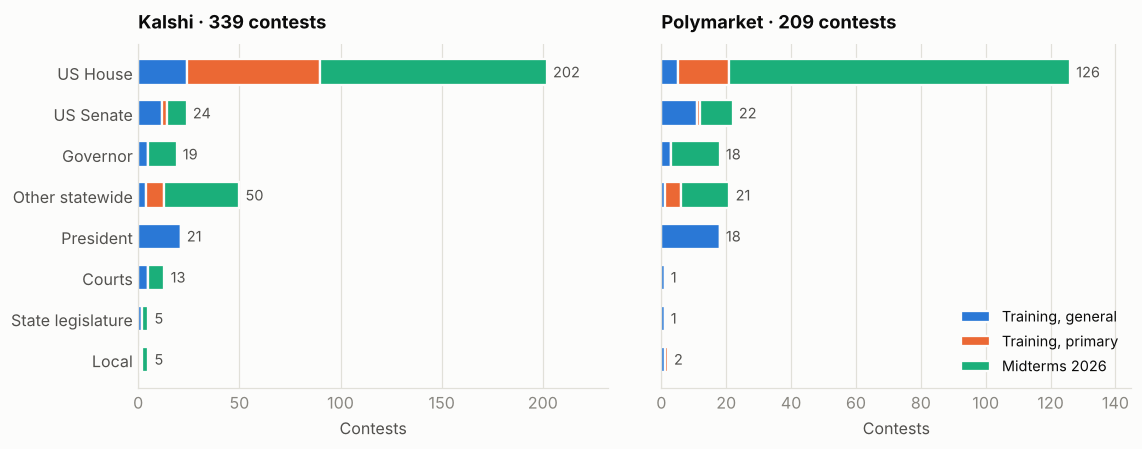

In [6]:
ORDER = ["US House", "US Senate", "Governor", "Other statewide", "President", "Courts", "State legislature", "Local"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
office_rows = []
for ax, platform in zip(axes, ("Kalshi", "Polymarket")):
    table = (contests[contests["platform"] == platform].groupby(["office", "group"]).size()
             .unstack(fill_value=0).reindex(index=ORDER[::-1], columns=list(GROUPS), fill_value=0))
    left = np.zeros(len(table))
    y = np.arange(len(table))
    for group, colour in GROUPS.items():
        ax.barh(y, table[group], left=left, height=0.62, color=colour, edgecolor=SURFACE, linewidth=1.5, label=group)
        left += table[group].to_numpy()
    for i, total in enumerate(left):
        if total:
            ax.text(total + left.max() * 0.015, i, str(int(total)), va="center", fontsize=9.5, color=INK_2)
    ax.set_yticks(y, table.index)
    ax.set_xlim(0, left.max() * 1.15)
    ax.set_title(f"{platform} · {int(left.sum())} contests", pad=10)
    ax.set_xlabel("Contests")
    value_grid(ax)
    office_rows.append(table.iloc[::-1].assign(platform=platform))
axes[1].legend(loc="lower right", fontsize=9.5)
fig.tight_layout(w_pad=3)
save(fig, "data_offices")
offices = pd.concat(office_rows)
offices.to_csv(TABLES / f"offices_{STAGE}.csv")
offices

## How much was traded

Lifetime traded volume per contest (log scale), with the median marked. Kalshi counts contracts, each paying $1 if it
wins; Polymarket counts dollars. The two are therefore not directly comparable, but each platform's groups are.

,platform,group,contests,unit,median,quartile 1,quartile 3
0,Kalshi,"Training, general",74,contracts,329916.0,42250.0,3830172.0
1,Kalshi,"Training, primary",78,contracts,8761.0,3252.0,19867.0
2,Kalshi,Midterms 2026,187,contracts,182722.0,27818.0,628653.0
3,Polymarket,"Training, general",41,dollars,1307430.0,247981.0,6369168.0
4,Polymarket,"Training, primary",23,dollars,38745.0,13519.0,100576.0
5,Polymarket,Midterms 2026,145,dollars,91370.0,48008.0,211199.0


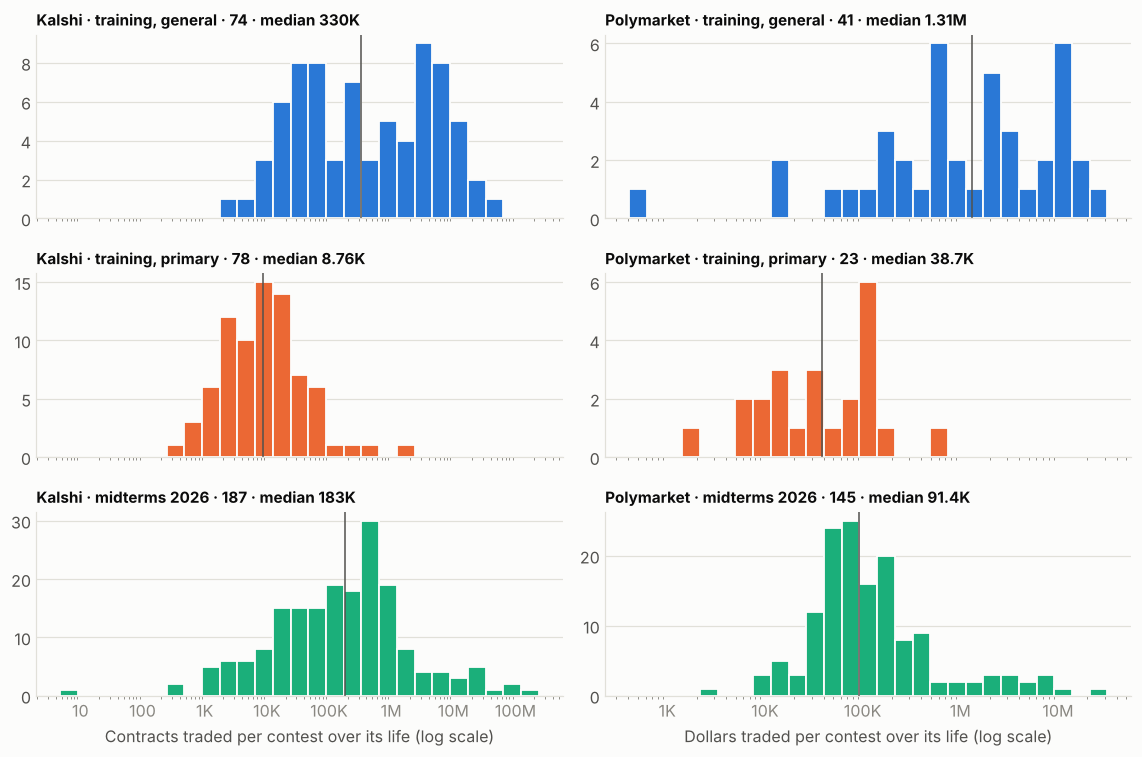

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(10.5, 7), sharex="col")
volume_rows = []
for col, (platform, unit) in enumerate((("Kalshi", "contracts"), ("Polymarket", "dollars"))):
    mine = contests[contests["platform"] == platform]
    low, high = np.log10(mine["volume"].clip(lower=1).min()) - 0.1, np.log10(mine["volume"].max()) + 0.1
    bins = np.logspace(low, high, 28)
    for row, (group, colour) in enumerate(GROUPS.items()):
        ax = axes[row, col]
        values = mine.loc[mine["group"] == group, "volume"].clip(lower=1)
        ax.hist(values, bins=bins, color=colour, edgecolor=SURFACE, linewidth=1.2)
        median = values.median()
        ax.axvline(median, color=INK_2, linewidth=1)
        ax.set_title(f"{platform} · {group.lower()} · {len(values)} · median {compact(median)}", fontsize=10)
        ax.set_xscale("log")
        value_grid(ax, "y")
        volume_rows.append({"platform": platform, "group": group, "contests": len(values), "unit": unit,
                            "median": median, "quartile 1": values.quantile(0.25), "quartile 3": values.quantile(0.75)})
    axes[2, col].xaxis.set_major_formatter(FuncFormatter(compact))
    axes[2, col].set_xlabel(f"{unit.capitalize()} traded per contest over its life (log scale)")
fig.tight_layout(h_pad=1.2)
save(fig, "data_volume")
volumes = pd.DataFrame(volume_rows)
volumes.to_csv(TABLES / f"volume_{STAGE}.csv", index=False)
volumes.round(0)

## How heavily favoured

The favourite's price at the snapshot, after the two candidate prices are scaled to add up to 1. By construction every
analysed contest lies between 50% and 95%.

count    25%    50%    75%
platform   group                                        
Kalshi     Midterms 2026      187.0  0.702  0.825  0.916
           Training, general   74.0  0.621  0.776  0.893
           Training, primary   78.0  0.770  0.855  0.915
Polymarket Midterms 2026      145.0  0.720  0.840  0.921
           Training, general   41.0  0.677  0.815  0.895
           Training, primary   23.0  0.796  0.865  0.915

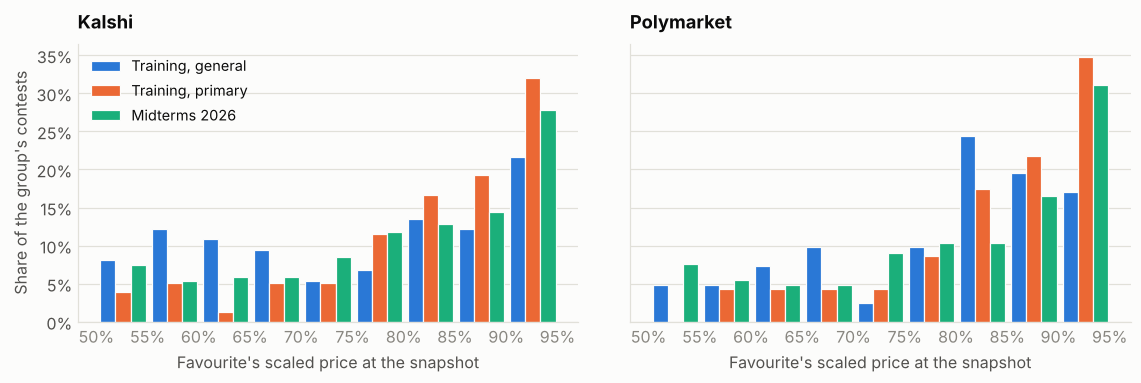

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
bins = np.arange(0.5, 0.95 + 1e-9, 0.05)
for ax, platform in zip(axes, ("Kalshi", "Polymarket")):
    mine = contests[contests["platform"] == platform]
    width = 0.05 / 3.4
    for k, (group, colour) in enumerate(GROUPS.items()):
        counts, _ = np.histogram(mine.loc[mine["group"] == group, "favourite"], bins=bins)
        share = counts / max(counts.sum(), 1)
        ax.bar(bins[:-1] + 0.004 + k * width, share, width=width, align="edge", color=colour, label=group,
               edgecolor=SURFACE, linewidth=0.8)
    ax.set_xticks(bins, [f"{b:.0%}" for b in bins])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(platform, pad=10)
    ax.set_xlabel("Favourite's scaled price at the snapshot")
    value_grid(ax, "y")
axes[0].set_ylabel("Share of the group's contests")
axes[0].legend(loc="upper left", fontsize=9.5)
fig.tight_layout(w_pad=3)
save(fig, "data_favourites")
contests.groupby(["platform", "group"])["favourite"].describe()[["count", "25%", "50%", "75%"]].round(3)